# LAB – Ensemble Models: Bagging e Boosting com o dataset Penguins

**PUC-SP – Ciência da Computação – Inteligência Artificial (IA ML)**

**Alunos (dupla):**
- João Avila Harduin - RA00332195
- Kauã Cordeiro Cavalheiro - RA00331660

**Objetivo:** implementar e comparar dois modelos de *ensemble* com Scikit-Learn:
1. **Bagging** – `BaggingClassifier` com árvores de decisão
2. **Boosting** – `GradientBoostingClassifier`

**Dataset:** [Penguins](https://vega.github.io/vega-datasets/) do Vega Datasets. São medidas de 344 pinguins de três espécies
(*Adelie*, *Chinstrap* e *Gentoo*) coletadas no arquipélago de Palmer, na Antártida.

**Problema:** classificação multiclasse, ou seja, prever a **espécie** do pinguim a partir das medidas do bico,
da nadadeira, da massa corporal, da ilha e do sexo.

## 1. Bibliotecas

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

RANDOM_STATE = 42

## 2. Carregando os dados

O pacote `vega_datasets` do pip é antigo e não traz o Penguins, por isso lemos o JSON direto do repositório oficial do Vega (via CDN jsDelivr).

In [2]:
URL = "https://cdn.jsdelivr.net/npm/vega-datasets/data/penguins.json"
df = pd.read_json(URL)

print("Dimensões:", df.shape)
df.head()

Dimensões: (344, 7)


,Species,Island,Beak Length (mm),Beak Depth (mm),Flipper Length (mm),Body Mass (g),Sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


## 3. Análise exploratória

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Species              344 non-null    str    
 1   Island               344 non-null    str    
 2   Beak Length (mm)     342 non-null    float64
 3   Beak Depth (mm)      342 non-null    float64
 4   Flipper Length (mm)  342 non-null    float64
 5   Body Mass (g)        342 non-null    float64
 6   Sex                  334 non-null    str    
dtypes: float64(4), str(3)
memory usage: 18.9 KB


In [4]:
print("Valores ausentes por coluna:")
print(df.isna().sum())
print("\nValores da coluna Sex:")
print(df["Sex"].value_counts(dropna=False))

Valores ausentes por coluna:
Species                 0
Island                  0
Beak Length (mm)        2
Beak Depth (mm)         2
Flipper Length (mm)     2
Body Mass (g)           2
Sex                    10
dtype: int64

Valores da coluna Sex:
Sex
MALE      168
FEMALE    165
NaN        10
.           1
Name: count, dtype: int64


Observações:
- Duas linhas não têm nenhuma medida, e a coluna `Sex` tem 10 valores ausentes.
- A coluna `Sex` tem um valor inválido `"."`, que vamos tratar como ausente.
- Não vamos apagar linhas. Os valores ausentes serão preenchidos por um `SimpleImputer` dentro do *pipeline*.

Distribuição das espécies (variável alvo):
Species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64


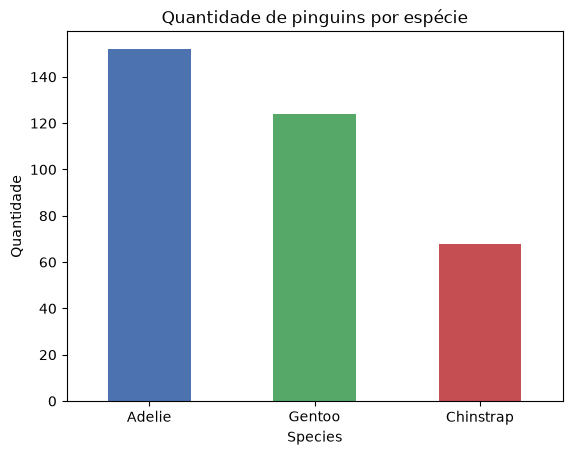

In [5]:
print("Distribuição das espécies (variável alvo):")
print(df["Species"].value_counts())

df["Species"].value_counts().plot(kind="bar", color=["#4C72B0", "#55A868", "#C44E52"])
plt.title("Quantidade de pinguins por espécie")
plt.ylabel("Quantidade")
plt.xticks(rotation=0)
plt.show()

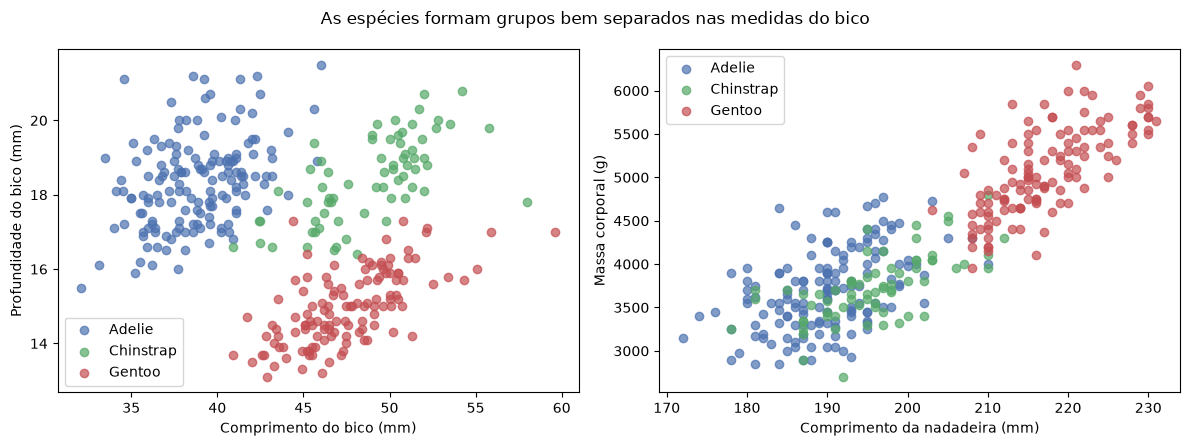

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
cores = {"Adelie": "#4C72B0", "Chinstrap": "#55A868", "Gentoo": "#C44E52"}

for especie, grupo in df.groupby("Species"):
    axes[0].scatter(grupo["Beak Length (mm)"], grupo["Beak Depth (mm)"], label=especie, alpha=0.7, c=cores[especie])
    axes[1].scatter(grupo["Flipper Length (mm)"], grupo["Body Mass (g)"], label=especie, alpha=0.7, c=cores[especie])

axes[0].set_xlabel("Comprimento do bico (mm)"); axes[0].set_ylabel("Profundidade do bico (mm)")
axes[1].set_xlabel("Comprimento da nadadeira (mm)"); axes[1].set_ylabel("Massa corporal (g)")
axes[0].legend(); axes[1].legend()
plt.suptitle("As espécies formam grupos bem separados nas medidas do bico")
plt.tight_layout()
plt.show()

In [7]:
pd.crosstab(df["Island"], df["Species"])

Species,Adelie,Chinstrap,Gentoo
Island,,,
Biscoe,44,0,124
Dream,56,68,0
Torgersen,52,0,0


A ilha já dá uma boa pista: os *Gentoo* aparecem apenas em Biscoe e os *Chinstrap* apenas em Dream.

## 4. Pré-processamento

- **Alvo (`y`):** `Species`
- **Features numéricas:** comprimento e profundidade do bico, comprimento da nadadeira e massa corporal. Os ausentes são preenchidos com a **mediana**.
- **Features categóricas:** `Island` e `Sex`. Os ausentes são preenchidos com o valor **mais frequente**, depois aplicamos **One-Hot Encoding**.

Árvores de decisão não precisam de normalização (`StandardScaler`), então não aplicamos escala.

In [8]:
df["Sex"] = df["Sex"].replace(".", np.nan)

features_num = ["Beak Length (mm)", "Beak Depth (mm)", "Flipper Length (mm)", "Body Mass (g)"]
features_cat = ["Island", "Sex"]

X = df[features_num + features_cat]
y = df["Species"]

preprocessador = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), features_num),
    ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"),
                          OneHotEncoder(handle_unknown="ignore")), features_cat),
])

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)
print("Treino:", X_train.shape, "| Teste:", X_test.shape)

Treino: (258, 6) | Teste: (86, 6)


## 5. Modelo de referência: uma única Árvore de Decisão

Antes dos *ensembles*, treinamos **uma única árvore** para servir de comparação.
Uma árvore sem limite de profundidade tende a ter **alta variância**: decora o treino e erra mais em dados novos.

In [10]:
arvore = Pipeline([
    ("prep", preprocessador),
    ("modelo", DecisionTreeClassifier(random_state=RANDOM_STATE)),
])
arvore.fit(X_train, y_train)

acc_arvore = accuracy_score(y_test, arvore.predict(X_test))
print(f"Acurácia da Árvore de Decisão única: {acc_arvore:.4f}")

Acurácia da Árvore de Decisão única: 0.9884


## 6. Modelo 1 – Bagging (`BaggingClassifier`)

**Como funciona:**
1. São geradas `n_estimators` amostras *bootstrap* do treino, isto é, sorteios **com reposição**.
2. Uma árvore de decisão é treinada em cada amostra, de forma **independente e paralela**.
3. Na previsão, cada árvore vota e vence a classe **mais votada**.

Como cada árvore vê dados um pouco diferentes, os erros delas se compensam e a **variância cai**.

Também usamos `oob_score=True`. Cada árvore deixa de fora cerca de 37% das amostras (*out-of-bag*), que servem como
uma validação "gratuita", sem usar o conjunto de teste.

In [11]:
bagging = Pipeline([
    ("prep", preprocessador),
    ("modelo", BaggingClassifier(
        estimator=DecisionTreeClassifier(),
        n_estimators=100,      # número de árvores no comitê
        max_samples=1.0,       # cada bootstrap tem o mesmo tamanho do treino
        bootstrap=True,        # amostragem com reposição
        oob_score=True,        # avaliação out-of-bag
        n_jobs=-1,             # treina as árvores em paralelo
        random_state=RANDOM_STATE,
    )),
])
bagging.fit(X_train, y_train)

y_pred_bag = bagging.predict(X_test)
acc_bag = accuracy_score(y_test, y_pred_bag)

print(f"OOB score (validação interna): {bagging.named_steps['modelo'].oob_score_:.4f}")
print(f"Acurácia no teste:             {acc_bag:.4f}\n")
print(classification_report(y_test, y_pred_bag))

OOB score (validação interna): 0.9806
Acurácia no teste:             1.0000

              precision    recall  f1-score   support

      Adelie       1.00      1.00      1.00        38
   Chinstrap       1.00      1.00      1.00        17
      Gentoo       1.00      1.00      1.00        31

    accuracy                           1.00        86
   macro avg       1.00      1.00      1.00        86
weighted avg       1.00      1.00      1.00        86



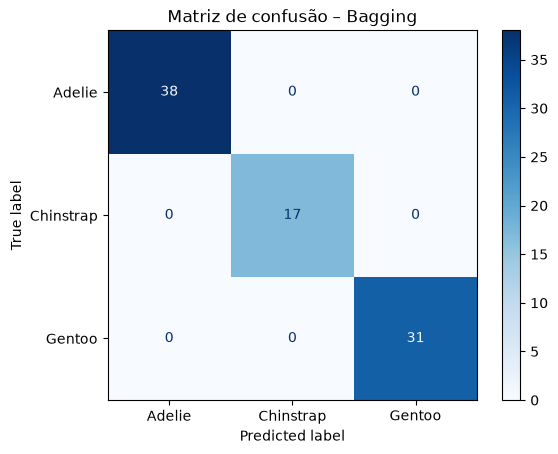

In [12]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_bag, cmap="Blues")
plt.title("Matriz de confusão – Bagging")
plt.show()

## 7. Modelo 2 – Boosting (`GradientBoostingClassifier`)

**Como funciona:**
1. Os modelos são treinados de forma **sequencial**, não em paralelo.
2. Cada nova árvore, pequena e rasa (um *weak learner*), é ajustada aos **resíduos**, ou seja, aos erros que o conjunto anterior ainda comete.
3. A contribuição de cada árvore é multiplicada pela `learning_rate`, para o modelo aprender aos poucos.
4. A previsão final é a **soma ponderada** de todas as árvores.

Assim o Boosting **reduz o viés**: transforma vários classificadores fracos em um classificador forte.
Para 3 classes, o Scikit-Learn treina uma árvore por classe em cada rodada.

In [13]:
boosting = Pipeline([
    ("prep", preprocessador),
    ("modelo", GradientBoostingClassifier(
        n_estimators=100,      # número de rodadas (árvores sequenciais)
        learning_rate=0.1,     # peso de cada nova árvore
        max_depth=3,           # árvores rasas = weak learners
        random_state=RANDOM_STATE,
    )),
])
boosting.fit(X_train, y_train)

y_pred_boost = boosting.predict(X_test)
acc_boost = accuracy_score(y_test, y_pred_boost)

print(f"Acurácia no teste: {acc_boost:.4f}\n")
print(classification_report(y_test, y_pred_boost))

Acurácia no teste: 1.0000

              precision    recall  f1-score   support

      Adelie       1.00      1.00      1.00        38
   Chinstrap       1.00      1.00      1.00        17
      Gentoo       1.00      1.00      1.00        31

    accuracy                           1.00        86
   macro avg       1.00      1.00      1.00        86
weighted avg       1.00      1.00      1.00        86



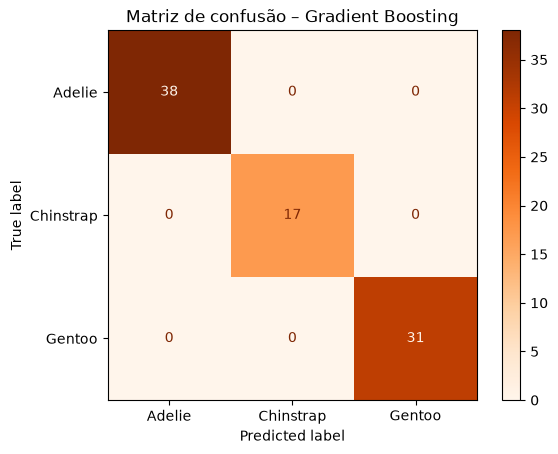

In [14]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_boost, cmap="Oranges")
plt.title("Matriz de confusão – Gradient Boosting")
plt.show()

### Importância das features no Boosting

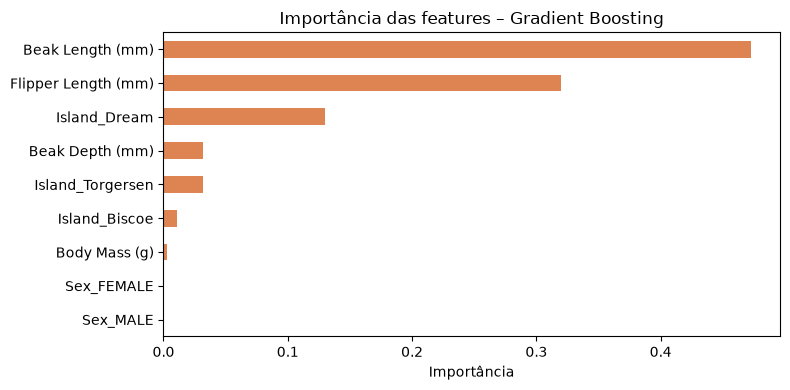

In [15]:
nomes = boosting.named_steps["prep"].get_feature_names_out()
nomes = [n.split("__")[1] for n in nomes]
importancias = pd.Series(boosting.named_steps["modelo"].feature_importances_, index=nomes).sort_values()

importancias.plot(kind="barh", color="#DD8452", figsize=(8, 4))
plt.title("Importância das features – Gradient Boosting")
plt.xlabel("Importância")
plt.tight_layout()
plt.show()

## 8. Comparação com validação cruzada

O teste tem só 86 amostras, então um único erro já muda a acurácia em mais de 1 ponto percentual.
Para uma comparação mais justa, usamos **validação cruzada estratificada com 5 *folds*** no dataset inteiro.

In [16]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
modelos = {
    "Árvore única": arvore,
    "Bagging": bagging,
    "Gradient Boosting": boosting,
}

resultados = []
for nome, modelo in modelos.items():
    scores = cross_val_score(modelo, X, y, cv=cv, scoring="accuracy")
    resultados.append({
        "Modelo": nome,
        "Acurácia no teste": accuracy_score(y_test, modelo.predict(X_test)),
        "CV média": scores.mean(),
        "CV desvio padrão": scores.std(),
    })

tabela = pd.DataFrame(resultados).set_index("Modelo")
tabela.style.format("{:.4f}")

,Acurácia no teste,CV média,CV desvio padrão
Modelo,,,
Árvore única,0.9884,0.9681,0.0249
Bagging,1.0000,0.9710,0.0224
Gradient Boosting,1.0000,0.9797,0.0148


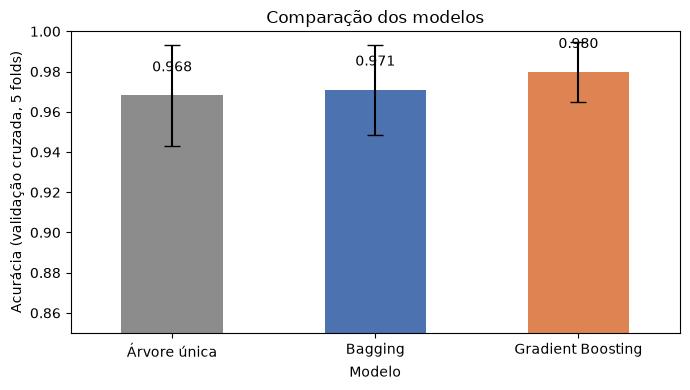

In [17]:
ax = tabela["CV média"].plot(kind="bar", yerr=tabela["CV desvio padrão"], capsize=6,
                             color=["#8C8C8C", "#4C72B0", "#DD8452"], figsize=(7, 4))
ax.set_ylim(0.85, 1.0)
ax.set_ylabel("Acurácia (validação cruzada, 5 folds)")
ax.set_title("Comparação dos modelos")
plt.xticks(rotation=0)
for i, v in enumerate(tabela["CV média"]):
    ax.text(i, v + 0.012, f"{v:.3f}", ha="center")
plt.tight_layout()
plt.show()

## 9. Conclusão

**Resultados (validação cruzada com 5 folds):**

| Modelo | Acurácia média | Desvio padrão |
|---|---|---|
| Árvore de Decisão única | ~96,8% | ~2,5% |
| Bagging | ~97,1% | ~2,2% |
| Gradient Boosting | ~98,0% | ~1,5% |

*(Os números exatos estão na tabela da seção 8.)*

**Análise:**
- O Penguins é um dataset **fácil**: as espécies ficam bem separadas pelas medidas do bico e pela ilha. Por isso até uma única árvore passa de 96%,
  e os dois *ensembles* acertaram **100% do conjunto de teste**. Como o teste tem só 86 pinguins, usamos a validação cruzada para comparar com mais segurança.
- O **Bagging** melhorou a árvore única e **reduziu o desvio padrão**, ou seja, o modelo ficou mais estável. É exatamente o objetivo do Bagging:
  **reduzir a variância** fazendo a média de várias árvores treinadas em amostras *bootstrap* diferentes. O *OOB score* (~98%) confirmou esse
  desempenho sem precisar do conjunto de teste.
- O **Gradient Boosting** teve a **maior acurácia média e o menor desvio**. Ele treina árvores rasas em sequência, e cada uma corrige os erros das
  anteriores, o que **reduz o viés**. A importância das features mostra que ele se apoia principalmente no comprimento do bico e no
  comprimento da nadadeira, coerente com os gráficos da análise exploratória.
- **Bagging × Boosting:** o Bagging treina em paralelo e é mais simples de ajustar. O Boosting é sequencial (mais lento de treinar) e tem mais
  hiperparâmetros (`learning_rate`, `max_depth`, `n_estimators`), mas costuma chegar a um resultado melhor, como aconteceu aqui.

## Referências

- Scikit-Learn – Ensemble methods: https://scikit-learn.org/stable/modules/ensemble.html
- BaggingClassifier: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.BaggingClassifier.html
- GradientBoostingClassifier: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.GradientBoostingClassifier.html
- GeeksforGeeks – Bagging vs Boosting vs Stacking: https://www.geeksforgeeks.org/machine-learning/bagging-vs-boosting-vs-stacking/
- GeeksforGeeks – Boosting in Machine Learning: https://www.geeksforgeeks.org/machine-learning/boosting-in-machine-learning/
- Vega Datasets: https://vega.github.io/vega-datasets/